| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../20_INVESTIGACION/20_2_Reproducir_papers.ipynb) | [⏩](../21_MATEMATICA_MAS_AVANZADA/21_1_Analisis_real.ipynb) |

# 20.3 DISEÑO EXPERIMENTAL EN SCIENTIFIC MACHINE LEARNING

Diseñar un experimento significa decidir qué variar, qué mantener fijo y qué medir para responder una pregunta. Si cambiamos datos, arquitectura y presupuesto a la vez, una diferencia de error no permite saber qué la causó. En SciML, además, hay que controlar solver, resolución, física utilizada y condiciones de evaluación.

Construiremos un diseño factorial con tres factores para un emulador del enfriamiento: cantidad de datos, ruido y uso de una penalización física. Cada configuración se repetirá con varias semillas, y las comparaciones se harán por bloques de semilla.

**Objetivos.** Formular hipótesis, identificar unidades experimentales, estimar efectos e interacciones y comunicar incertidumbre. Bibliotecas: NumPy, SciPy y Matplotlib. Los datos se generan localmente y la solución exacta se usa solo para evaluación.

## 1. Pregunta y métrica antes de ejecutar

Pregunta: «¿cómo cambian el error de solución y la sensibilidad al ruido al añadir un residual físico, con pocos o muchos datos?» La métrica primaria será RMSE en una malla de prueba de la solución $u(t)=e^{-0.7t}$. El residual físico y el error de entrenamiento son métricas secundarias.

La hipótesis concreta es que la penalización mejora RMSE especialmente con pocos datos y ruido alto **cuando la ecuación usada es correcta**. No pretende concluir sobre toda PINN ni sobre ecuaciones mal especificadas. El ajuste usará una base polinómica lineal para reducir confusión con optimización no convexa.

## 2. Factores, niveles y controles

| Factor | Nivel bajo | Nivel alto |
| --- | --- | --- |
| Número de observaciones | 16 | 64 |
| Desviación del ruido | 0.02 | 0.08 |
| Penalización física | $\lambda=0$ | $\lambda=1$ |

Son $2^3=8$ configuraciones. Mantendremos grado seis, tiempo final dos, física $k=0.7$, condición inicial exacta y malla de colocación de 60 puntos. Cambiar estos valores abre otra pregunta y debe registrarse como otro experimento.

Los puntos de entrenamiento y ruido se generan por semilla. Dentro de una semilla compartiremos entradas para comparar métodos de manera pareada. Las 64 observaciones contienen a las 16 como subconjunto, por lo que las condiciones no son independientes dentro del bloque; tendremos eso en cuenta al calcular incertidumbre.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import product
from scipy.stats import ttest_rel
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "font.size": 11})
T, k, grado, n_col, repeticiones = 2.0, 0.7, 6, 60, 24
t_test = np.linspace(0, T, 401)
u_test = np.exp(-k*t_test)

def bases(t):
    s = np.asarray(t)/T; j = np.arange(1, grado+1)
    return s[:, None]**j[None, :], j[None, :]/T*s[:, None]**(j[None, :]-1)

phi_test, dphi_test = bases(t_test)
phi_f, dphi_f = bases(np.linspace(0, T, n_col))

def ajuste(t_obs, y_obs, lam):
    phi_d, _ = bases(t_obs)
    A = np.vstack([phi_d/np.sqrt(len(t_obs)), np.sqrt(lam/n_col)*(dphi_f+k*phi_f)])
    b = np.r_[(y_obs-1)/np.sqrt(len(t_obs)), -np.sqrt(lam/n_col)*k*np.ones(n_col)]
    return np.linalg.lstsq(A, b, rcond=None)[0]

## 3. Unidad experimental y pseudorreplicación

Una repetición independiente será una nueva semilla que genera nuevos datos y ruido. Los 401 puntos de prueba no son 401 repeticiones independientes: pertenecen a la misma curva predicha. Tratar cada punto como una repetición subestimaría la incertidumbre del rendimiento.

También debemos distinguir repetir un solver determinista con idénticas entradas de repetir datos o inicializaciones. Si el algoritmo determinista devuelve exactamente la misma salida, ejecutar cien veces no añade evidencia sobre generalización; puede servir para medir tiempo, pero esa es otra unidad y otra métrica.

## 4. Aleatorización y bloqueo

Aleatorizar el orden de ejecución evita asociar un método sistemáticamente con condiciones distintas de carga o temperatura del equipo. Bloquear por semilla reduce variabilidad al comparar métodos sobre los mismos datos. El bloqueo no elimina la necesidad de repetir semillas.

Usaremos orden aleatorio dentro de cada bloque y guardaremos resultados en un índice fijo de configuración. No seleccionaremos hiperparámetros con la prueba: los dos niveles de $\lambda$ forman parte del diseño definido previamente.

In [2]:
configuraciones = list(product([16, 64], [0.02, 0.08], [0.0, 1.0]))
resultados = np.empty((repeticiones, 8, 3))  # RMSE prueba, MSE datos, MSE física.
for seed in range(repeticiones):
    rr = np.random.default_rng(3000+seed)
    t_base = rr.uniform(0.02, T, 64)
    ruido_base = rr.normal(size=64)
    orden_ejecucion = rr.permutation(8)
    for j in orden_ejecucion:
        n, sigma, lam = configuraciones[j]
        t_obs = t_base[:n]
        y_obs = np.exp(-k*t_obs)+sigma*ruido_base[:n]
        c = ajuste(t_obs, y_obs, lam)
        pred = 1+phi_test @ c
        derivada = dphi_test @ c
        phi_d, _ = bases(t_obs)
        resultados[seed, j] = [
            np.sqrt(np.mean((pred-u_test)**2)),
            np.mean((1+phi_d @ c-y_obs)**2),
            np.mean((derivada+k*pred)**2)
        ]
print("Experimentos ejecutados:", repeticiones*len(configuraciones))
for j, conf in enumerate(configuraciones):
    print(conf, "RMSE medio ± desviación:", resultados[:, j, 0].mean(), resultados[:, j, 0].std(ddof=1))

Experimentos ejecutados: 192
(16, 0.02, 0.0) RMSE medio ± desviación: 0.045612795839495505 0.13531619346124932
(16, 0.02, 1.0) RMSE medio ± desviación: 0.001688999617603561 0.001182353854568101
(16, 0.08, 0.0) RMSE medio ± desviación: 0.18245190252129703 0.5412685262034788
(16, 0.08, 1.0) RMSE medio ± desviación: 0.006756012066116296 0.00472938285229176
(64, 0.02, 0.0) RMSE medio ± desviación: 0.006084168276520907 0.0025474150172574575
(64, 0.02, 1.0) RMSE medio ± desviación: 0.0008860812621108146 0.000557965545170634
(64, 0.08, 0.0) RMSE medio ± desviación: 0.024336675865915054 0.010189662179201184
(64, 0.08, 1.0) RMSE medio ± desviación: 0.003544317383154024 0.002231861442262668


## 5. La variabilidad forma parte del resultado

Informar solo el mejor valor oculta la sensibilidad a datos. Mostraremos distribución entre semillas y medias por configuración. La desviación entre semillas describe variabilidad de rendimiento; el error estándar de la media es esa desviación dividida por $\sqrt B$ bajo bloques independientes.

La escala de error puede ser asimétrica, especialmente cuando un ajuste polinómico sin regularización se vuelve inestable. Por eso también usaremos logaritmo de RMSE para efectos factoriales; el cambio de escala debe declararse y afecta interpretación.

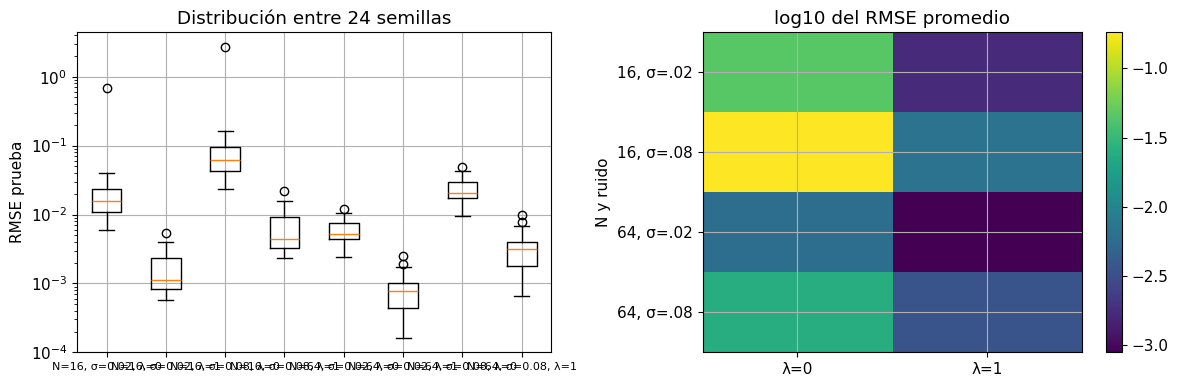

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
labels = [f"N={n}, σ={s}, λ={l:g}" for n, s, l in configuraciones]
axes[0].boxplot([resultados[:, j, 0] for j in range(8)], tick_labels=labels, showfliers=True)
axes[0].set_yscale("log")
axes[0].set(ylabel="RMSE prueba", title="Distribución entre 24 semillas")
axes[0].tick_params(axis="x", labelsize=8)
medias = resultados[:, :, 0].mean(axis=0).reshape(2, 2, 2)
# Filas: combinación N/ruido; columnas: penalización.
im = axes[1].imshow(np.log10(medias.reshape(4, 2)), cmap="viridis", aspect="auto")
axes[1].set_xticks([0, 1], ["λ=0", "λ=1"])
axes[1].set_yticks(range(4), ["16, σ=.02", "16, σ=.08", "64, σ=.02", "64, σ=.08"])
axes[1].set(title="log10 del RMSE promedio", ylabel="N y ruido")
fig.colorbar(im, ax=axes[1]); plt.tight_layout(); plt.show()

## 6. Efectos principales e interacciones

Codificamos cada nivel como $-1$ o $+1$. Para respuesta $z=\log(\mathrm{RMSE})$, un modelo factorial completo es
$$z=\beta_0+\beta_Nx_N+\beta_\sigma x_\sigma+\beta_\lambda x_\lambda+\beta_{N\sigma}x_Nx_\sigma+\beta_{N\lambda}x_Nx_\lambda+\beta_{\sigma\lambda}x_\sigma x_\lambda+\beta_{N\sigma\lambda}x_Nx_\sigma x_\lambda.$$
En un diseño equilibrado, el efecto alto menos bajo promedio es $2\beta$ para un factor. Una interacción indica que el efecto de un factor depende de otro; no es una «corrección» que deba descartarse por complicar la historia.

Calcularemos coeficientes por semilla y haremos bootstrap de bloques completos. Así preservamos el pareo y las dependencias entre configuraciones dentro de la misma semilla.

Efecto principal de física: -2.3032227185650096 Razón geométrica aproximada: 0.09993625776690211


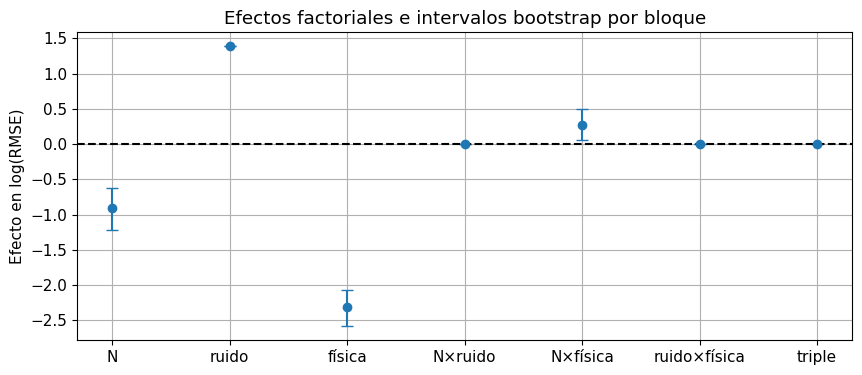

In [4]:
niveles = np.array(list(product([-1, 1], repeat=3)), dtype=float)
a, b, c = niveles.T
D = np.column_stack([np.ones(8), a, b, c, a*b, a*c, b*c, a*b*c])
respuesta = np.log(np.maximum(resultados[:, :, 0], 1e-15))
betas = np.linalg.solve(D, respuesta.T).T
# Cada fila de betas proviene de un bloque completo.
efectos = 2*betas[:, 1:]
rr_boot = np.random.default_rng(999)
idx_boot = rr_boot.integers(0, repeticiones, size=(2000, repeticiones))
efectos_boot = efectos[idx_boot].mean(axis=1)
lo, hi = np.quantile(efectos_boot, [0.025, 0.975], axis=0)
med = efectos.mean(axis=0)
etiquetas = ["N", "ruido", "física", "N×ruido", "N×física", "ruido×física", "triple"]
fig, ax = plt.subplots(figsize=(10, 4))
ax.errorbar(np.arange(7), med, yerr=[med-lo, hi-med], fmt="o", capsize=4)
ax.axhline(0, color="k", ls="--")
ax.set_xticks(range(7), etiquetas)
ax.set(ylabel="Efecto en log(RMSE)", title="Efectos factoriales e intervalos bootstrap por bloque")
plt.show()
print("Efecto principal de física:", med[2], "Razón geométrica aproximada:", np.exp(med[2]))

## 7. Interpretar el efecto y su intervalo

Un efecto negativo en log(RMSE) indica que el nivel alto reduce la respuesta promedio en esa escala. Exponenciar un efecto da una razón geométrica de errores. Si una interacción es grande, el efecto principal promedio puede ocultar comportamientos distintos en subgrupos.

Los intervalos bootstrap reflejan variabilidad entre las 24 semillas del protocolo. No incorporan incertidumbre sobre otras PDEs, bibliotecas, niveles de ruido o modelos físicos. La evidencia responde a la pregunta definida y a los rangos estudiados.

## 8. Comparación pareada preespecificada

Como contraste concreto, compararemos $\lambda=0$ y $\lambda=1$ para $N=16$, $\sigma=0.08$. Cada par usa las mismas observaciones. La diferencia $\Delta=E_0-E_1$ es positiva si física reduce RMSE.

Calcularemos diferencia media e intervalo bootstrap, además de una prueba t pareada como diagnóstico bajo sus supuestos. Un p-valor no mide importancia práctica ni probabilidad de que una hipótesis sea cierta. El tamaño del efecto y sus límites son centrales; el protocolo no se cambia después de observar el resultado.

Mejora media RMSE (datos solos - física): 0.17569589045518075
Intervalo bootstrap 95%: [0.05367227 0.40545567]
Prueba t pareada, bilateral: TtestResult(statistic=np.float64(1.5889543669166384), pvalue=np.float64(0.1257238527469848), df=np.int64(23))


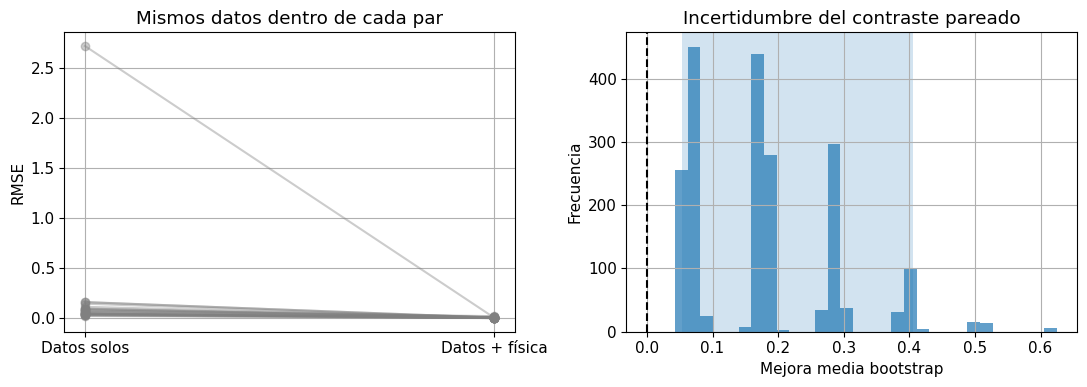

In [5]:
j0 = configuraciones.index((16, 0.08, 0.0))
j1 = configuraciones.index((16, 0.08, 1.0))
e0, e1 = resultados[:, j0, 0], resultados[:, j1, 0]
dif = e0-e1
boot_dif = dif[idx_boot].mean(axis=1)
ci = np.quantile(boot_dif, [0.025, 0.975])
print("Mejora media RMSE (datos solos - física):", dif.mean())
print("Intervalo bootstrap 95%:", ci)
print("Prueba t pareada, bilateral:", ttest_rel(e0, e1))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for s in range(repeticiones):
    axes[0].plot([0, 1], [e0[s], e1[s]], "o-", color="gray", alpha=0.4)
axes[0].set_xticks([0, 1], ["Datos solos", "Datos + física"])
axes[0].set(ylabel="RMSE", title="Mismos datos dentro de cada par")
axes[1].hist(boot_dif, bins=30, alpha=0.7)
axes[1].axvline(0, color="k", ls="--")
axes[1].axvspan(ci[0], ci[1], alpha=0.2)
axes[1].set(xlabel="Mejora media bootstrap", ylabel="Frecuencia", title="Incertidumbre del contraste pareado")
plt.tight_layout(); plt.show()

## 9. Visualizar interacciones

Si el beneficio de física aumenta con el ruido, las curvas de error frente a ruido tendrán pendientes distintas. Si cambia con cantidad de datos, el contraste puede ser distinto para 16 y 64 observaciones. Un solo promedio mezcla esas situaciones.

La figura siguiente mantiene cada combinación visible. Las barras son errores estándar entre semillas, no rangos de observaciones individuales ni intervalos de predicción.

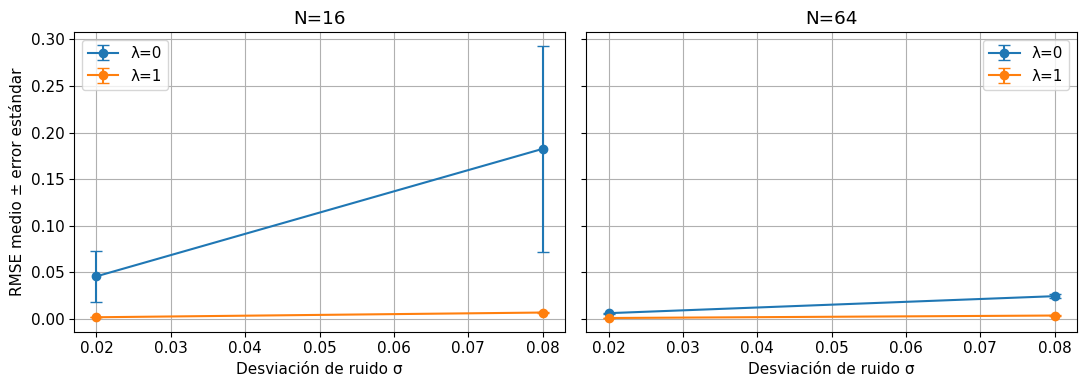

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, n in zip(axes, [16, 64]):
    for lam in [0.0, 1.0]:
        ids = [configuraciones.index((n, sig, lam)) for sig in [0.02, 0.08]]
        vals = resultados[:, ids, 0]
        ax.errorbar([0.02, 0.08], vals.mean(axis=0), yerr=vals.std(axis=0, ddof=1)/np.sqrt(repeticiones), fmt="o-", capsize=4, label=f"λ={lam:g}")
    ax.set(xlabel="Desviación de ruido σ", title=f"N={n}")
    ax.legend()
axes[0].set_ylabel("RMSE medio ± error estándar")
plt.tight_layout(); plt.show()

## 10. Potencia, número de repeticiones y presupuesto

Más repeticiones reducen incertidumbre de efectos, pero no arreglan un diseño sesgado. Una simulación piloto puede estimar desviación de una diferencia pareada. Si esa desviación es $s_\Delta$, el error estándar de su media es $s_\Delta/\sqrt B$; reducirlo a la mitad requiere aproximadamente cuatro veces más bloques.

Elegir presupuesto exige definir qué efecto sería científicamente importante. Un efecto minúsculo puede producir p-valor pequeño con muchas repeticiones sin justificar uso práctico. En experimentos caros conviene estudiar primero referencias, factores dominantes y un diseño reducido informado.

## 11. Ablations, controles y sesgo de selección

Una ablation elimina un componente, como el residual físico. Un control positivo comprueba recuperación en un problema conocido; un control negativo puede imponer física incorrecta para ver si la supuesta mejora depende del conocimiento correcto.

Probar decenas de arquitecturas y reportar solo la mejor sobre prueba produce optimismo. Separa entrenamiento, validación para decisiones y prueba final. Si la misma familia de ecuaciones se usa para todo, aclara que no se evaluó transferencia a nuevas familias.

## 12. Costo y comparabilidad

Igualar épocas no siempre iguala costo: derivadas físicas pueden ser más caras por paso. Una comparación útil puede reportar error frente a evaluaciones del solver, tiempo y memoria. El costo de generar datos debe incluirse cuando sea parte del objetivo.

Nuestro experimento usa mínimos cuadrados y no redes profundas; estudia efecto de datos y residual en una clase controlada. Sus resultados no predicen directamente la velocidad ni el comportamiento de optimización de una PINN.

| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../20_INVESTIGACION/20_2_Reproducir_papers.ipynb) | [⏩](../21_MATEMATICA_MAS_AVANZADA/21_1_Analisis_real.ipynb) |